In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Consistent visualization style
sns.set_theme(style="whitegrid", palette="deep")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [3]:
DATA_PATH = Path("../data/raw/ai4i2020.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape[0]:,} rows")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully: 10,000 rows
Number of columns: 14


In [5]:
display(df.head())
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:


,Data type
UDI,int64
Product ID,str
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [6]:
missing_summary = pd.DataFrame({
    "Missing count": df.isnull().sum(),
    "Missing percentage": (
        df.isnull().mean() * 100
    ).round(2),
})

display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())

,Missing count,Missing percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


Duplicate rows: 0


In [7]:
TARGET = "Machine failure"

print("Target values:", sorted(df[TARGET].unique()))

print("\nFailure counts:")
display(df[TARGET].value_counts().sort_index())

print("\nFailure percentages:")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentage")
)

Target values: [np.int64(0), np.int64(1)]

Failure counts:


Machine failure
0    9661
1     339
Name: count, dtype: int64


Failure percentages:


Machine failure
0    96.61
1     3.39
Name: Percentage, dtype: float64

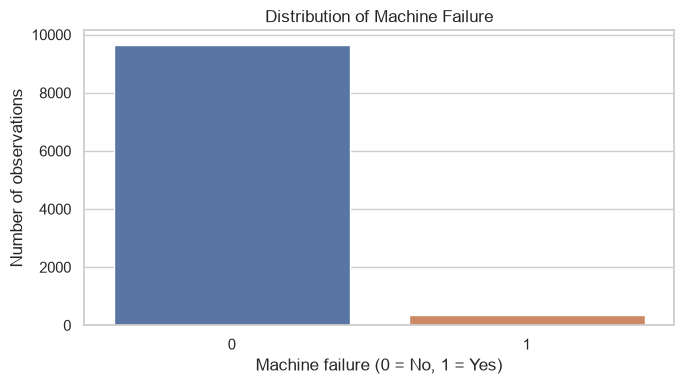

In [8]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x=TARGET,
    hue=TARGET,
    legend=False,
)

ax.set_title("Distribution of Machine Failure")
ax.set_xlabel("Machine failure (0 = No, 1 = Yes)")
ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

In [9]:
TARGET = "Machine failure"

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

CATEGORICAL_FEATURES = ["Type"]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Input feature shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9
